# Data fusion rule experiment

Compare built-in PyDI fusion rules on the medicine groups in `fusion_eval_worksheet.csv`.


## Experiment setup

Describe your experiment setup here: the rules you will test, why you chose them, the evaluation data, and the comparisons you plan to make.

In [73]:
import logging
from decimal import Decimal
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PyDI.fusion import (
    DataFusionEngine, DataFusionStrategy, DataFusionEvaluator,
    longest_string, voting, union,
    tokenized_match, set_equality_match, exact_match,
)
from PyDI.fusion.engine import build_record_groups_from_correspondences
from PyDI.fusion.base import _is_valid_value

logging.basicConfig(level=logging.WARNING)
project_root = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'data/8_fusion_eval').is_dir()
)
work_dir = project_root / 'notebooks/data_fusion_skeleton'
input_path = project_root / 'data/8_fusion_eval/fusion_eval_worksheet.csv'
attributes = [
    'brandName', 'activeSubstances', 'activeSubstanceCount', 'licenceHolder',
    'productClass', 'atcCode', 'dosageForm', 'route', 'strengths', 'biosimilar',
]
set_attributes = ['activeSubstances', 'atcCode', 'dosageForm', 'route', 'strengths']
text_attributes = ['brandName', 'licenceHolder']

## Load evaluation data

Split each `src_*` cell at source boundaries, retaining the source IDs supplied by the worksheet.

- `activeSubstances`, `atcCode`, `dosageForm`, `route`: `list[str]`
- `strengths`: `list[tuple[str, str | None]]` (amount or range, unit)
- `activeSubstanceCount`: `int`
- `biosimilar`: `bool`
- Empty cells: `None`

In [74]:
def load_fusion_eval_set(path):
    """Load and prepare the evaluation set for PyDI fusion-rule experiments."""
    # Load CSV
    worksheet = pd.read_csv(path, sep=';', dtype=str, keep_default_na=False)
    source_rows = {source: [] for source in ['DPD', 'EMA', 'FDA']}
    gold_rows = []
    pair_rows = []

    for row in worksheet.to_dict('records'):
        # Split Source Values
        source_values = {}
        for attribute in attributes:
            source_values[attribute] = dict(
                part.split(': ', 1)
                for part in row['src_' + attribute].split(' | ') if part
            )

        # Build Source Records
        members = []
        records = []
        for source in source_rows:
            record_id = row[source.lower() + '_id']
            if record_id:
                members.append(record_id)
                record = {'id': record_id}
                record.update({
                    attribute: source_values[attribute].get(source, '')
                    for attribute in attributes
                })
                records.append((source, record))

        # Build Gold Record
        gold = {'id': row['eval_id']}
        gold.update({attribute: row['gold_' + attribute] for attribute in attributes})
        records.append(('gold', gold))

        # Convert Types
        for source, record in records:
            for attribute in attributes:
                value = record[attribute].strip()
                if not value:
                    # Empty cell -> None
                    record[attribute] = None
                elif attribute == 'strengths':
                    # strengths -> list of (amount text, unit) pairs
                    strengths = []
                    for item in value.split('; '):
                        parts = item.split(maxsplit=1)
                        # Normalize numeric text and preserve range endpoints.
                        amount = '-'.join(
                            format(Decimal(bound).normalize(), 'f')
                            for bound in parts[0].replace('–', '-').split('-')
                        )
                        strengths.append((amount, parts[1] if len(parts) > 1 else None))
                    record[attribute] = strengths
                elif attribute in set_attributes:
                    # activeSubstances, atcCode, dosageForm, route -> list[str]
                    record[attribute] = value.split('; ')
                elif attribute == 'activeSubstanceCount':
                    # activeSubstanceCount -> int
                    record[attribute] = int(value)
                elif attribute == 'biosimilar':
                    # biosimilar -> bool
                    record[attribute] = value.lower() == 'true'
                else:
                    # brandName, licenceHolder, productClass -> str
                    record[attribute] = value
            if source == 'gold':
                gold_rows.append(record)
            else:
                source_rows[source].append(record)

        # Link Group Members
        for member in members[1:]:
            pair_rows.append((members[0], member, 1.0))  # Positive link indicator.

    # Build PyDI Inputs
    datasets = {}
    for source, records in source_rows.items():
        frame = pd.DataFrame(records, columns=['id', *attributes], dtype=object)
        frame = frame.drop_duplicates('id').reset_index(drop=True)
        frame.attrs.update(dataset_name=source, trust_score=1.0)
        datasets[source] = frame

    correspondences = pd.DataFrame(pair_rows, columns=['id1', 'id2', 'similarity'])
    gold = pd.DataFrame(gold_rows, columns=['id', *attributes], dtype=object)
    return datasets, correspondences, gold

In [75]:
datasets, correspondences, gold = load_fusion_eval_set(input_path)
display(pd.DataFrame({
    'source': list(datasets),
    'records': [len(frame) for frame in datasets.values()],
}))
print(f'Worksheet groups: {len(gold)} | Links: {len(correspondences)}')
display(gold.head())

,source,records
0,DPD,28
1,EMA,28
2,FDA,28


Worksheet groups: 36 | Links: 48


,id,brandName,activeSubstances,activeSubstanceCount,licenceHolder,productClass,atcCode,dosageForm,route,strengths,biosimilar
0,FDA_AGENERASE|AMPRENAVIR,AGENERASE,[amprenavir],1,GlaxoSmithKline,Human,[J05AE05],"[Capsule, Solution]",[Oral],"[(50, mg), (150, mg), (15, mg/mL)]",False
1,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,BOSULIF,[bosutinib],1,PF Prism C.V.,Human,[L01EA04],"[Capsule, Tablet]",[Oral],"[(50, mg), (100, mg), (400, mg), (500, mg)]",False
2,FDA_CINQAIR|RESLIZUMAB,CINQAIR,[reslizumab],1,"Teva Respiratory, LLC",Human,[R03DX08],[Injection],[Intravenous],"[(10, mg/mL)]",False
3,FDA_ELELYSO|TALIGLUCERASE ALFA,ELELYSO,[taliglucerase alfa],1,Pfizer Inc.,Human,[A16AB11],[Powder for solution],[Intravenous],"[(200, U)]",False
4,FDA_HEMLIBRA|EMICIZUMAB,HEMLIBRA,[emicizumab],1,"Genentech, Inc.",Human,[B02BX06],[Injection],[Subcutaneous],"[(30, mg/mL), (150, mg/mL)]",False


## Fusion rules

Simple fusion rules:

- Text: longest string.
- Categories and counts: voting.
- Sets: union.

Fixed evaluation comparisons:

- Text: normalized word sets.
- Lists: equal members, ignoring order and case.
- Strengths: equal amount–unit pairs.
- Counts and booleans: exact match.

In [76]:
def compare_set(actual, expected):
    """Compare normalized set members while preserving strength pairs."""
    if actual is None or expected is None:
        return actual is None and expected is None

    # Normalize Names
    # Strength tuples keep their amounts and units.
    actual = {item if isinstance(item, tuple) else str(item).strip().casefold() for item in actual}
    expected = {item if isinstance(item, tuple) else str(item).strip().casefold() for item in expected}

    # Compare Sets
    return set_equality_match(actual, expected)

In [77]:
fusion_rules = {
    'brandName': longest_string,
    'activeSubstances': union,
    'activeSubstanceCount': voting,
    'licenceHolder': longest_string,
    'productClass': voting,
    'atcCode': union,
    'dosageForm': union,
    'route': union,
    'strengths': union,
    'biosimilar': voting,
}
display(pd.Series({attribute: rule.__name__ for attribute, rule in fusion_rules.items()},
                  name='fusion_rule').to_frame())

comparison_rules = {
    attribute: compare_set if attribute in set_attributes
    else tokenized_match if attribute in text_attributes else exact_match
    for attribute in attributes
}

,fusion_rule
brandName,longest_string
activeSubstances,union
activeSubstanceCount,voting
licenceHolder,longest_string
productClass,voting
atcCode,union
dosageForm,union
route,union
strengths,union
biosimilar,voting


## Run fusion

Fuse the evaluation groups using the simple rules defined above.

In [78]:
# Define Strategy
strategy = DataFusionStrategy('Simple rules')
for attribute, rule in fusion_rules.items():
    strategy.add_attribute_fuser(attribute, rule)
    strategy.add_evaluation_function(attribute, comparison_rules[attribute])

# Fuse Records
fused = DataFusionEngine(strategy).run(
    list(datasets.values()), correspondences,
    id_column='id', include_singletons=True,
)

# Align Gold IDs
gold_ids = set(gold['id'])
fused['eval_id'] = fused['_fusion_sources'].apply(
    lambda members: next(member for member in members if member in gold_ids)
)

# Calculate Accuracy
metrics = DataFusionEvaluator(strategy).evaluate(
    fused_df=fused[['eval_id', *attributes]], fused_id_column='eval_id',
    expected_df=gold, expected_id_column='id',
)
results = pd.DataFrame([{
    'strategy': strategy.name, 'overall_accuracy': metrics['overall_accuracy'],
    **{attribute + '_accuracy': metrics[attribute + '_accuracy'] for attribute in attributes},
}]).set_index('strategy')
display(results[['overall_accuracy']].round(4))

,overall_accuracy
strategy,
Simple rules,0.675


## Density and consistency

$N$ is the number of records in each source or fused dataset, $A=10$, and $G_a$ is the number of multi-source groups with a value for attribute $a$.

- **Attribute density:**

$$
D_a = \frac{\text{populated values for attribute }a}{N}
$$

- **Overall density:**

$$
D = \frac{\text{populated attribute cells}}{N \times A}
$$

- **Attribute consistency:**

$$
C_a = \frac{\text{groups with agreeing values for attribute }a}{G_a}
$$

In [79]:
density_columns = {}
for name, frame in {**datasets, 'Fused': fused}.items():
    density_columns[name] = frame[attributes].map(_is_valid_value).mean()
density = pd.DataFrame(density_columns)
display(density.round(3))

groups = build_record_groups_from_correspondences(
    list(datasets.values()), correspondences, id_column='id',
)
consistency_rows = []
for attribute in attributes:
    agreements = []
    for group in groups:
        values = [record[attribute] for record in group.records
                  if _is_valid_value(record[attribute])]
        if len(group.records) > 1 and values:
            agreements.append(all(comparison_rules[attribute](values[0], value)
                                  for value in values[1:]))
    consistency_rows.append({
        'attribute': attribute, 'consistency': pd.Series(agreements, dtype=float).mean(),
        'groups_with_values': len(agreements),
    })
consistency = pd.DataFrame(consistency_rows).set_index('attribute')
display(consistency.round(3))

,DPD,EMA,FDA,Fused
brandName,1.000,1.0,1.000,1.000
activeSubstances,1.000,1.0,1.000,1.000
activeSubstanceCount,1.000,1.0,1.000,1.000
licenceHolder,1.000,1.0,1.000,1.000
productClass,1.000,1.0,1.000,1.000
atcCode,0.964,1.0,0.000,0.972
dosageForm,1.000,0.0,0.786,0.944
route,1.000,0.0,0.821,0.972
strengths,1.000,0.0,1.000,1.000
biosimilar,1.000,1.0,0.000,1.000


,consistency,groups_with_values
attribute,,
brandName,0.806,36
activeSubstances,0.778,36
activeSubstanceCount,1.000,36
licenceHolder,0.000,36
productClass,1.000,36
atcCode,0.914,35
dosageForm,0.676,34
route,0.800,35
strengths,0.528,36


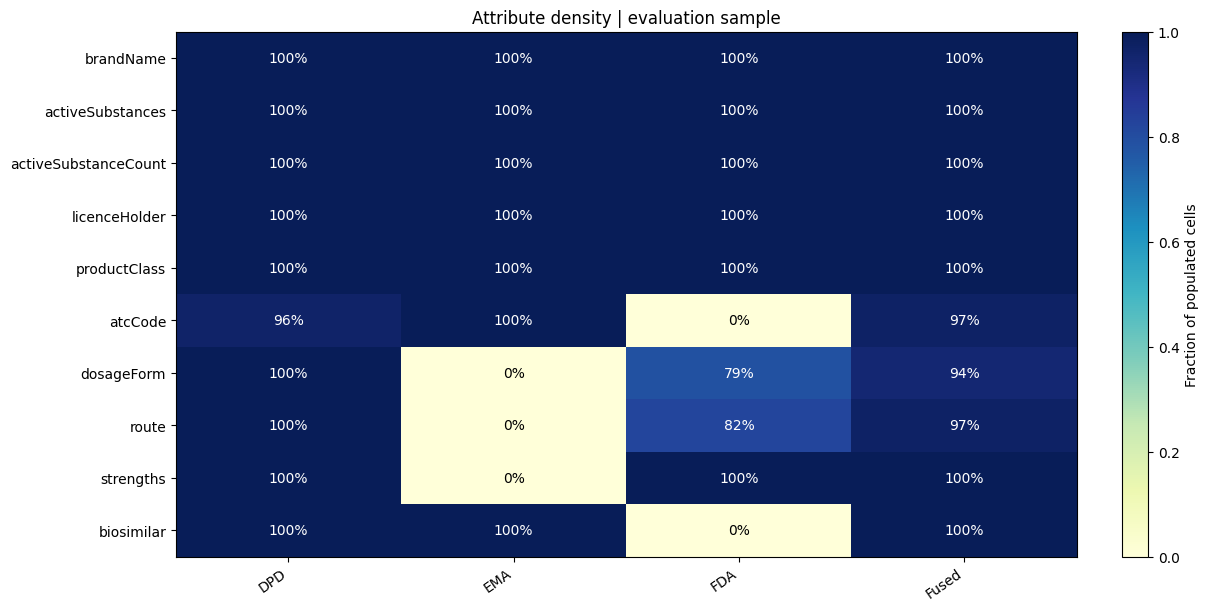

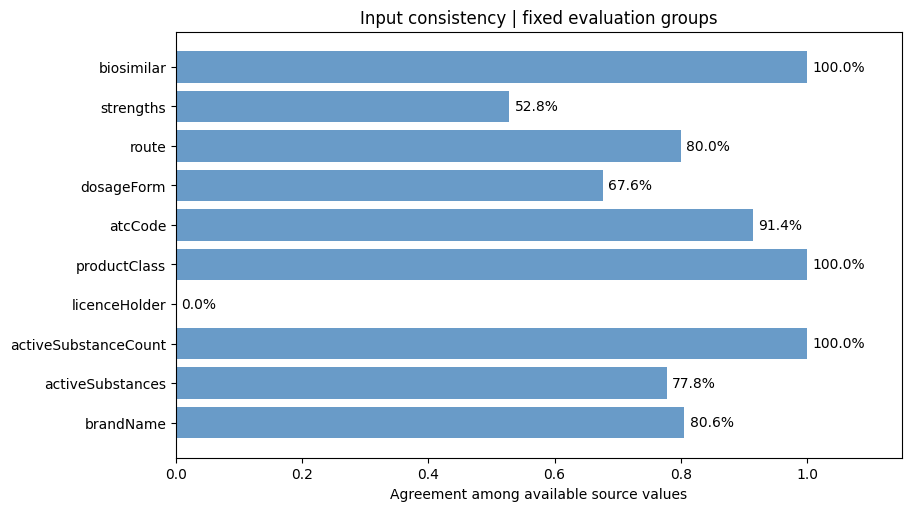

In [80]:
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
image = ax.imshow(density, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(density.columns)), density.columns, rotation=35, ha='right')
ax.set_yticks(range(len(attributes)), attributes)
for i in range(len(attributes)):
    for j in range(len(density.columns)):
        value = density.iloc[i, j]
        ax.text(j, i, f'{value:.0%}', ha='center', va='center',
                color='white' if value > 0.65 else 'black')
ax.set_title('Attribute density | evaluation sample')
fig.colorbar(image, ax=ax, label='Fraction of populated cells')
fig.savefig(work_dir / 'fusion_density.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
bars = ax.barh(consistency.index, consistency['consistency'], color='#699bc8')
ax.bar_label(bars, labels=[f'{value:.1%}' for value in consistency['consistency']], padding=4)
ax.set_xlim(0, 1.15)
ax.set_xlabel('Agreement among available source values')
ax.set_title('Input consistency | fixed evaluation groups')
fig.savefig(work_dir / 'fusion_consistency.png', dpi=200, bbox_inches='tight')
plt.show()

## Accuracy

Evaluate the fused records using $N=36$ medicines and $A=10$ gold attributes.

- **Attribute accuracy:**

$$
\mathrm{Accuracy}_a = \frac{\text{correct fused values for attribute }a}{N}
$$

- **Overall accuracy:**

$$
\mathrm{Accuracy} = \frac{\text{correct fused attribute values}}{N \times A}
$$

,accuracy
brandName,0.8056
activeSubstances,0.6667
activeSubstanceCount,1.0000
licenceHolder,0.0278
productClass,1.0000
atcCode,0.7778
dosageForm,0.4167
route,0.7222
strengths,0.3333
biosimilar,1.0000


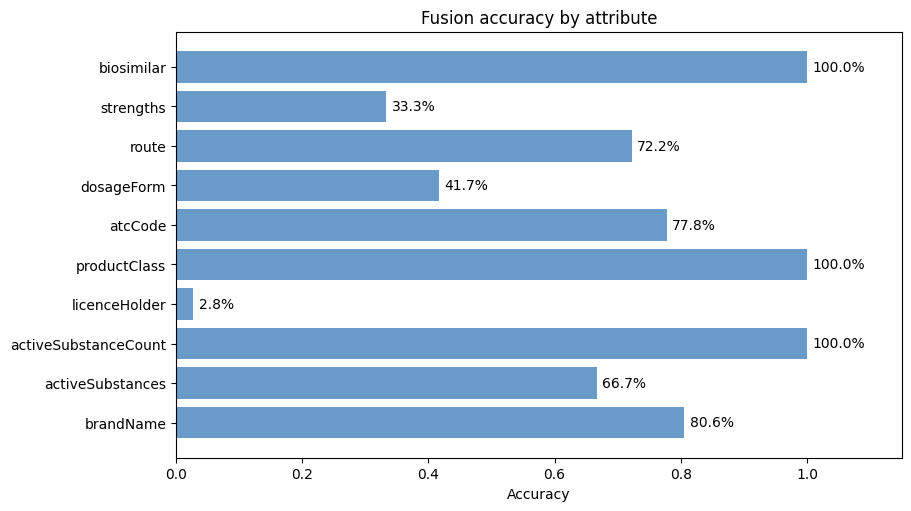

In [81]:
accuracy = pd.DataFrame({
    'accuracy': {attribute: metrics[attribute + '_accuracy'] for attribute in attributes}
})
display(accuracy.round(4))

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
bars = ax.barh(accuracy.index, accuracy['accuracy'], color='#699bc8')
ax.bar_label(bars, labels=[f'{value:.1%}' for value in accuracy['accuracy']], padding=4)
ax.set_xlim(0, 1.15)
ax.set_xlabel('Accuracy')
ax.set_title('Fusion accuracy by attribute')
fig.savefig(work_dir / 'fusion_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()

## Error review

Compare source values, fused values and gold values to identify remaining errors.

In [82]:
review_output = fused.set_index('eval_id')
expected = gold.set_index('id')
error_rows = []
for eval_id, reference in expected.iterrows():
    for attribute in attributes:
        actual = review_output.at[eval_id, attribute]
        target = reference[attribute]
        if not comparison_rules[attribute](actual, target):
            source_values = {}
            for source, frame in datasets.items():
                members = review_output.at[eval_id, '_fusion_sources']
                source_values[source] = frame.loc[frame['id'].isin(members), attribute].tolist()
            error_rows.append({
                'eval_id': eval_id, 'attribute': attribute,
                'rule': fusion_rules[attribute].__name__,
                'fused_value': actual, 'gold_value': target, **source_values,
            })
errors = pd.DataFrame(error_rows)
display(errors.head(20))

,eval_id,attribute,rule,fused_value,gold_value,DPD,EMA,FDA
0,FDA_AGENERASE|AMPRENAVIR,licenceHolder,longest_string,GLAXOSMITHKLINE INC,GlaxoSmithKline,[GLAXOSMITHKLINE INC],[Glaxo Group Ltd.],[GLAXOSMITHKLINE]
1,FDA_AGENERASE|AMPRENAVIR,dosageForm,union,"[Capsule, Liquid, Solution]","[Capsule, Solution]","[[Capsule, Liquid]]",[None],"[[Capsule, Solution]]"
2,FDA_AGENERASE|AMPRENAVIR,strengths,union,"[(15, mg), (15, mg/mL), (150, mg), (50, mg)]","[(50, mg), (150, mg), (15, mg/mL)]","[[(50, mg), (150, mg), (15, mg)]]",[None],"[[(150, mg), (15, mg/mL), (50, mg)]]"
3,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,activeSubstances,union,"[BOSUTINIB, BOSUTINIB MONOHYDRATE, bosutinib (...",[bosutinib],[[BOSUTINIB]],[[bosutinib (as monohydrate)]],[[BOSUTINIB MONOHYDRATE]]
4,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,licenceHolder,longest_string,Pfizer Europe MA EEIG,PF Prism C.V.,[PFIZER CANADA ULC],[Pfizer Europe MA EEIG],[PF PRISM CV]
5,FDA_CINQAIR|RESLIZUMAB,brandName,longest_string,Cinqaero,CINQAIR,[CINQAIR],[Cinqaero],[CINQAIR]
6,FDA_CINQAIR|RESLIZUMAB,dosageForm,union,"[Injection, Solution]",[Injection],[[Solution]],[None],[[Injection]]
7,FDA_CINQAIR|RESLIZUMAB,route,union,"[Injection, Intravenous]",[Intravenous],[[Intravenous]],[None],[[Injection]]
8,FDA_CINQAIR|RESLIZUMAB,strengths,union,"[(10, mg), (10, mg/mL)]","[(10, mg/mL)]","[[(10, mg)]]",[None],"[[(10, mg/mL)]]"
9,FDA_ELELYSO|TALIGLUCERASE ALFA,licenceHolder,longest_string,PFIZER CANADA ULC,Pfizer Inc.,[PFIZER CANADA ULC],[Pfizer Ltd.],[PFIZER]


## Save results

Save metrics, errors and figures alongside the notebook.

In [83]:
results.to_csv(work_dir / 'fusion_strategy_metrics.csv')
accuracy.to_csv(work_dir / 'fusion_attribute_accuracy.csv')
density.to_csv(work_dir / 'fusion_density.csv')
consistency.to_csv(work_dir / 'fusion_consistency.csv')
errors.to_csv(work_dir / 'fusion_errors.csv', index=False)
print(f'Experiment outputs: {work_dir}')

Experiment outputs: C:\Users\LENOVO\Documents\Personal\Study\Master\Mannheim University\HWS 2026\IE 670 Web Data Integration\wdi-drug-integration\notebooks\data_fusion_experiment
